## ML - HVAC Project

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# generating a synthetic data
np.random.seed(42)
n = 1500

df = pd.DataFrame({
    "Temperature": np.random.normal(27, 5, n),
    "Humidity": np.random.normal(55, 12, n),
    "Vibration": np.random.normal(2, 1, n),
    "Pressure": np.random.normal(100, 10, n),
    "Energy_Consumption": np.random.normal(500, 100, n),
    "Runtime_Hours": np.random.uniform(100, 3000, n)
})

risk_score = (
    (df["Temperature"] > 35).astype(int)
    + (df["Humidity"] > 75).astype(int)
    + (df["Vibration"] > 3.5).astype(int)
    + (df["Pressure"] < 85).astype(int)
    + (df["Energy_Consumption"] > 650).astype(int)
    + (df["Runtime_Hours"] > 2500).astype(int)
)

df["Failure"] = (risk_score >= 2).astype(int)

In [3]:
df.head()

,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours,Failure
0,29.483571,64.340333,0.092192,90.412215,388.591864,2872.457160,0
1,26.308678,48.385771,1.139615,86.474913,436.906917,722.731863,0
2,30.238443,45.181613,1.586394,84.164116,405.793982,1598.326354,0
3,34.615149,54.959507,3.887688,104.129989,445.200418,2234.450368,0
4,25.829233,52.957785,2.556553,97.859323,478.584969,1714.848798,0


In [4]:
df.tail()

,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours,Failure
1495,37.030464,55.929766,3.677377,101.714693,449.973898,1492.774084,1
1496,37.307518,58.093030,1.194828,111.526481,448.388336,2624.191403,1
1497,33.041831,40.098873,3.076848,87.825962,712.455623,1142.390576,0
1498,32.120313,59.010117,-0.169677,104.679504,222.618506,2787.451763,0
1499,29.962635,53.136891,0.805811,88.297193,482.038028,2126.105242,0


In [5]:
print("Dataset shape:", df.shape)
print("\nFailure distribution:")
print(df["Failure"].value_counts())

Dataset shape: (1500, 7)

Failure distribution:
Failure
0    1383
1     117
Name: count, dtype: int64


In [6]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Columns:
['Temperature', 'Humidity', 'Vibration', 'Pressure', 'Energy_Consumption', 'Runtime_Hours', 'Failure']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Temperature         1500 non-null   float64
 1   Humidity            1500 non-null   float64
 2   Vibration           1500 non-null   float64
 3   Pressure            1500 non-null   float64
 4   Energy_Consumption  1500 non-null   float64
 5   Runtime_Hours       1500 non-null   float64
 6   Failure             1500 non-null   int64  
dtypes: float64(6), int64(1)
memory usage: 82.2 KB

Statistical summary:


,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours,Failure
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,27.245248,55.179425,1.956176,99.673371,498.333221,1549.380119,0.078000
std,4.951116,11.800975,1.015719,10.021939,103.322676,830.329346,0.268261
min,10.793663,18.765854,-1.007632,68.232962,177.898364,100.698536,0.000000
25%,23.879843,47.375065,1.264330,93.202320,426.279380,821.547131,0.000000
50%,27.252015,54.975502,1.978924,99.751365,496.025199,1553.543592,0.000000
75%,30.400367,63.048346,2.612384,106.448435,570.416299,2270.727364,0.000000
max,46.263657,102.114852,5.243093,131.129102,852.905519,2999.052295,1.000000


Task 1 — Data Preprocessing

In [7]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values in each column:
Temperature           0
Humidity              0
Vibration             0
Pressure              0
Energy_Consumption    0
Runtime_Hours         0
Failure               0
dtype: int64

Number of duplicate rows:
0

Data types:
Temperature           float64
Humidity              float64
Vibration             float64
Pressure              float64
Energy_Consumption    float64
Runtime_Hours         float64
Failure                 int64
dtype: object


In [8]:
features = [
    "Temperature",
    "Humidity",
    "Vibration",
    "Pressure",
    "Energy_Consumption",
    "Runtime_Hours"
]

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"{col}: {len(outliers)} potential outliers")

Temperature: 10 potential outliers
Humidity: 18 potential outliers
Vibration: 10 potential outliers
Pressure: 17 potential outliers
Energy_Consumption: 7 potential outliers
Runtime_Hours: 0 potential outliers


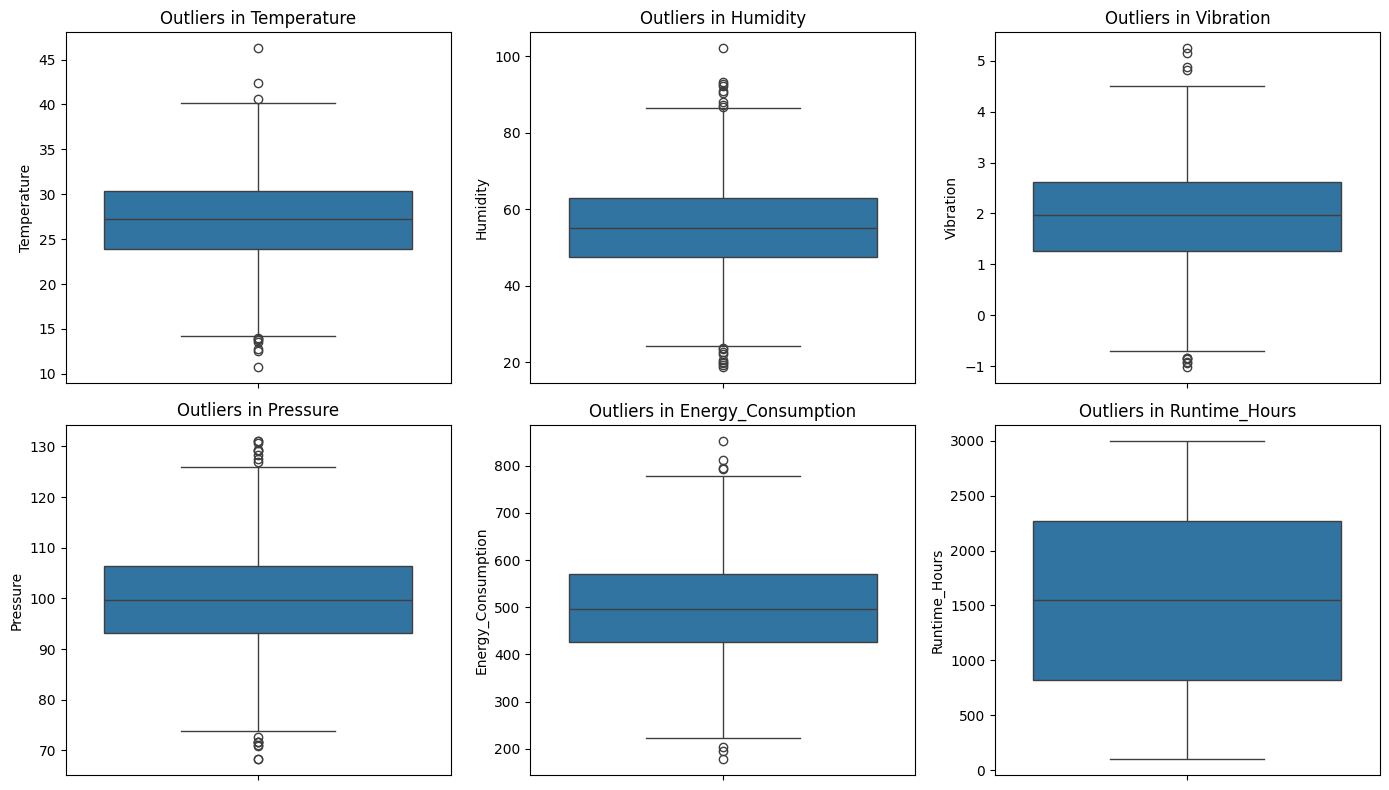

In [9]:
plt.figure(figsize=(14, 8))

for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"Outliers in {col}")

plt.tight_layout()
plt.show()

In [10]:
# Create a copy of the original dataset
df_clean = df.copy()

features = [
    "Temperature",
    "Humidity",
    "Vibration",
    "Pressure",
    "Energy_Consumption",
    "Runtime_Hours"
]

for col in features:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier capping completed!")

Outlier capping completed!


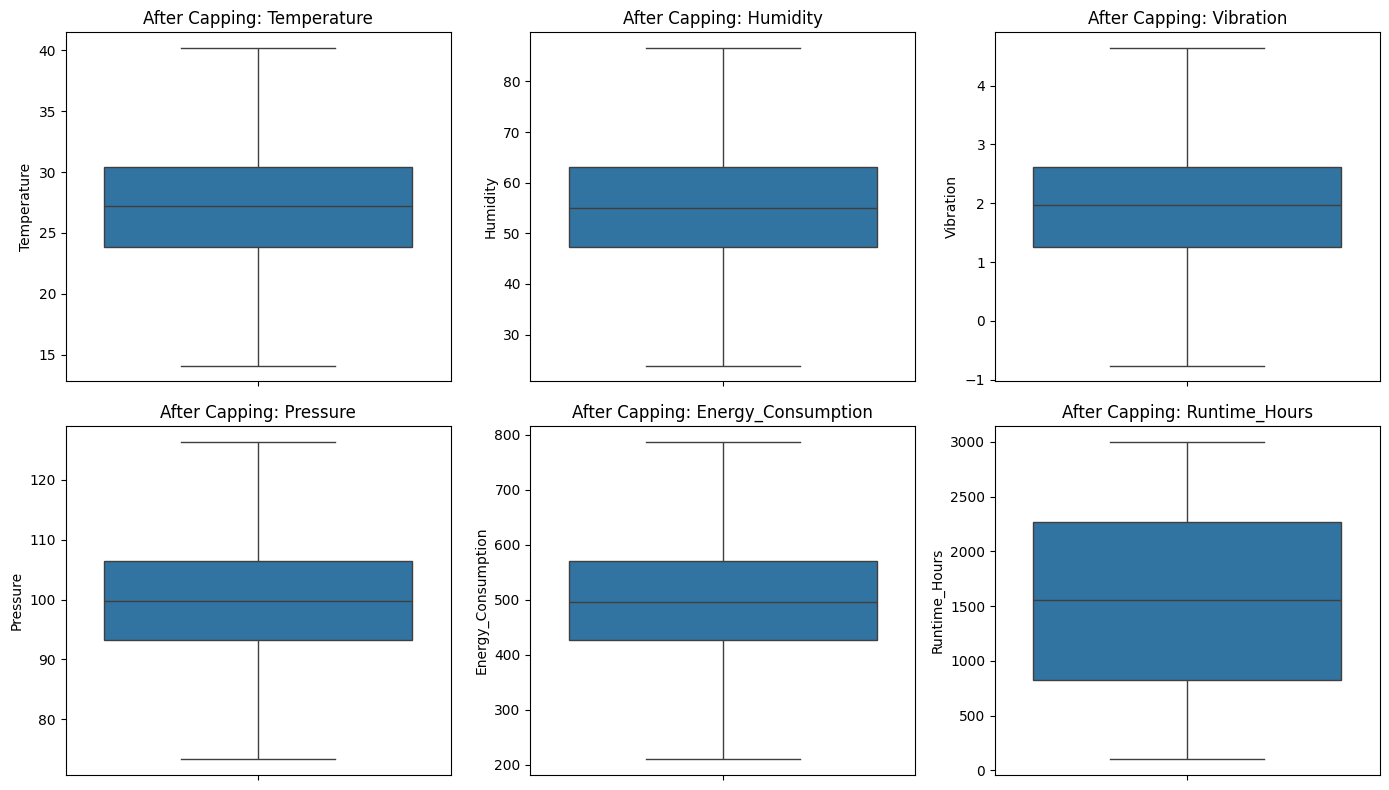

In [11]:
plt.figure(figsize=(14, 8))

for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_clean[col])
    plt.title(f"After Capping: {col}")

plt.tight_layout()
plt.show()

In [12]:
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after capping:")
print(df_clean.isnull().sum())

print("\nFailure distribution:")
print(df_clean["Failure"].value_counts())

Original dataset shape: (1500, 7)
Cleaned dataset shape: (1500, 7)

Missing values after capping:
Temperature           0
Humidity              0
Vibration             0
Pressure              0
Energy_Consumption    0
Runtime_Hours         0
Failure               0
dtype: int64

Failure distribution:
Failure
0    1383
1     117
Name: count, dtype: int64


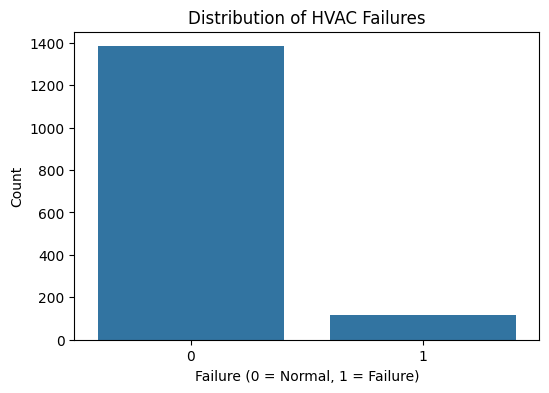

In [13]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x="Failure")

plt.title("Distribution of HVAC Failures")
plt.xlabel("Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Count")

plt.show()

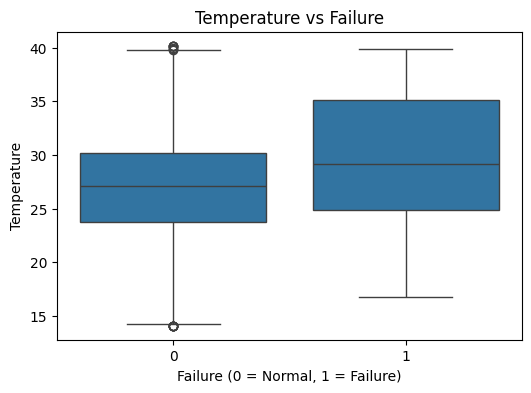

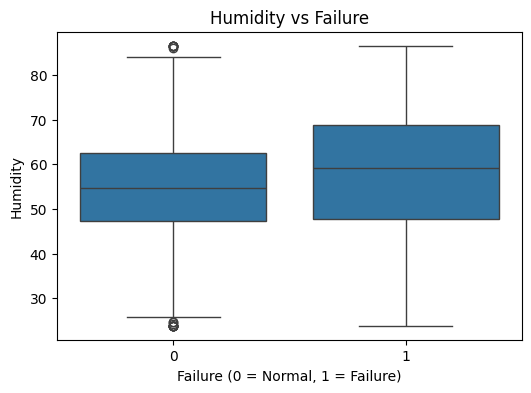

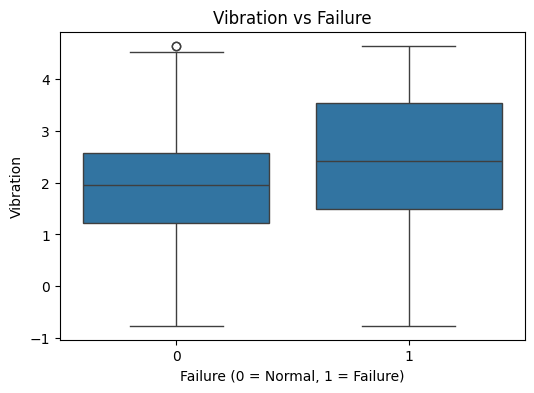

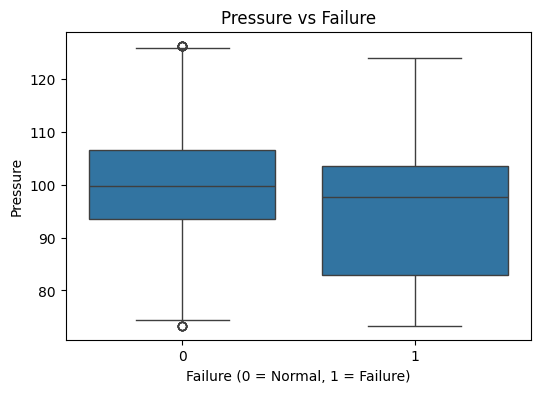

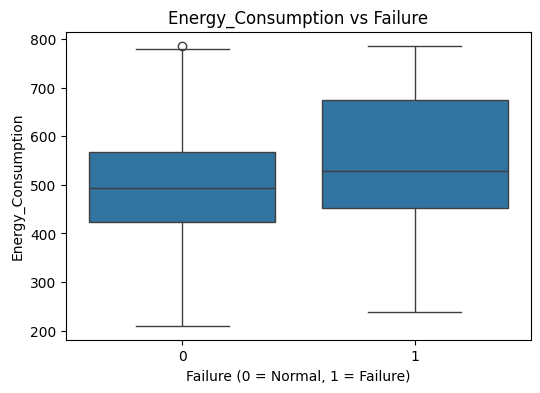

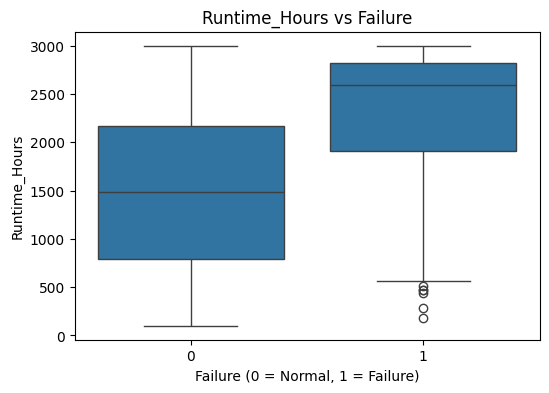

In [14]:
for col in features:
    plt.figure(figsize=(6, 4))

    sns.boxplot(data=df_clean, x="Failure", y=col)

    plt.title(f"{col} vs Failure")
    plt.xlabel("Failure (0 = Normal, 1 = Failure)")
    plt.ylabel(col)

    plt.show()

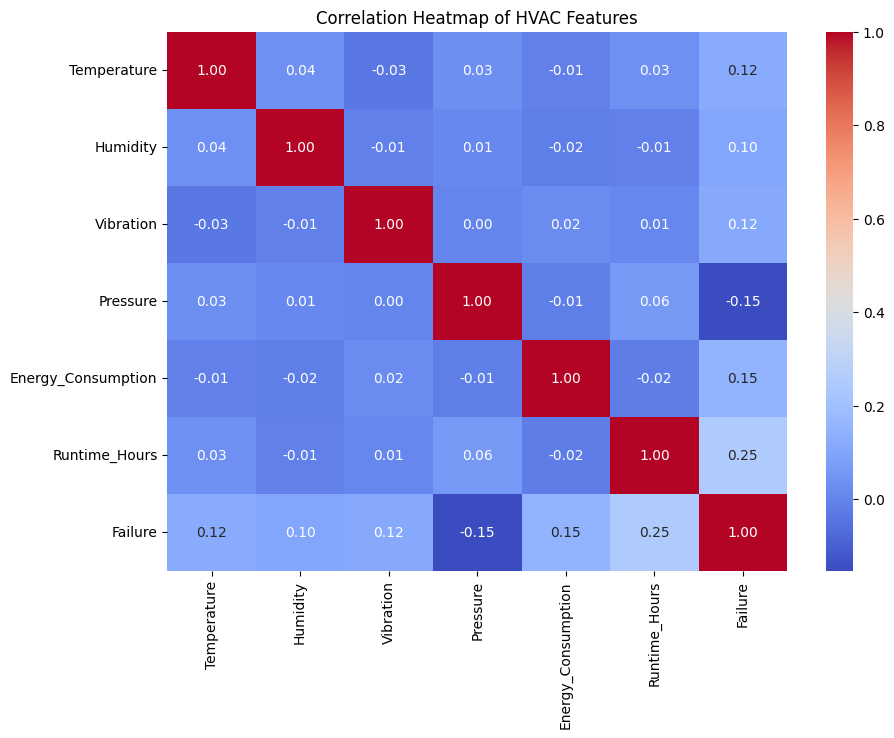

In [15]:
plt.figure(figsize=(10, 7))

correlation = df_clean.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of HVAC Features")
plt.show()

Task 2 — Feature Engineering

In [16]:
# Create a copy for feature engineering
df_fe = df_clean.copy()

# Feature 1: Temperature deviation from the simulated reference
df_fe["Temperature_Deviation"] = abs(df_fe["Temperature"] - 27)  # the absolute difference between each temperature and the reference value of 27

# Feature 2: Energy consumption per runtime hour
df_fe["Energy_Per_Runtime"] = (df_fe["Energy_Consumption"] /df_fe["Runtime_Hours"]) #a ratio between energy consumption and runtime

print("New features created successfully!")

display(df_fe.head())

New features created successfully!


,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours,Failure,Temperature_Deviation,Energy_Per_Runtime
0,29.483571,64.340333,0.092192,90.412215,388.591864,2872.457160,0,2.483571,0.135282
1,26.308678,48.385771,1.139615,86.474913,436.906917,722.731863,0,0.691322,0.604521
2,30.238443,45.181613,1.586394,84.164116,405.793982,1598.326354,0,3.238443,0.253887
3,34.615149,54.959507,3.887688,104.129989,445.200418,2234.450368,0,7.615149,0.199244
4,25.829233,52.957785,2.556553,97.859323,478.584969,1714.848798,0,1.170767,0.279083


In [17]:
print("Dataset shape after feature engineering:", df_fe.shape)

Dataset shape after feature engineering: (1500, 9)


In [18]:
# Input features
X = df_fe.drop(columns=["Failure"])

# Target variable
y = df_fe["Failure"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (1500, 8)
Target shape: (1500,)


In [19]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X, y)

print("Random Forest trained successfully!")

Random Forest trained successfully!


,Feature,Importance
5,Runtime_Hours,0.245672
4,Energy_Consumption,0.145413
3,Pressure,0.138494
2,Vibration,0.137553
0,Temperature,0.099002
1,Humidity,0.088928
7,Energy_Per_Runtime,0.086240
6,Temperature_Deviation,0.058699


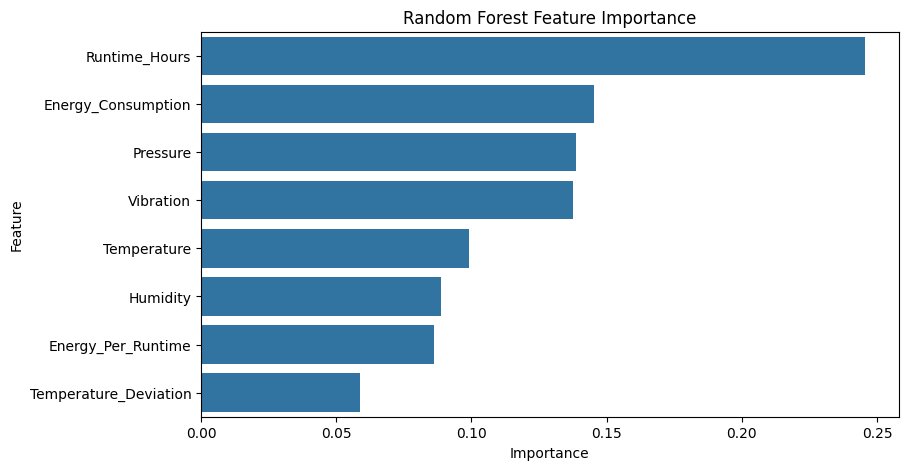

In [20]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

Task 3: Model Development

In [21]:
X = df_fe.drop(columns=["Failure"])
y = df_fe["Failure"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (1500, 8)
Target shape: (1500,)


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [23]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1200, 8)
Testing data: (300, 8)


* Logistic Regression

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [25]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

lr_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


* Random Forest

In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Task 4: Model Evaluation and Interpretation

In [27]:
# Logistic Regression predictions
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# Random Forest predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [28]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)

results = []

# Logistic Regression
results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_lr, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lr)
})

# Random Forest
results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf, zero_division=0),
    "Recall": recall_score(y_test, y_pred_rf, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_rf, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
})

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.800,0.266,0.913,0.412,0.915
1,Random Forest,0.953,1.000,0.391,0.562,0.996


Logistic Regression
Recall: 91.3% · Precision: 26.6%
It detects most of the actual failure cases, which is useful for predictive maintenance. However, its low precision means it also raises many false alarms.

Random Forest
Recall: 39.1% · Precision: 100%
Every observation it predicted as a failure was a true failure in this test set. But it detected only 39.1% of all actual failures, so it missed many failures.

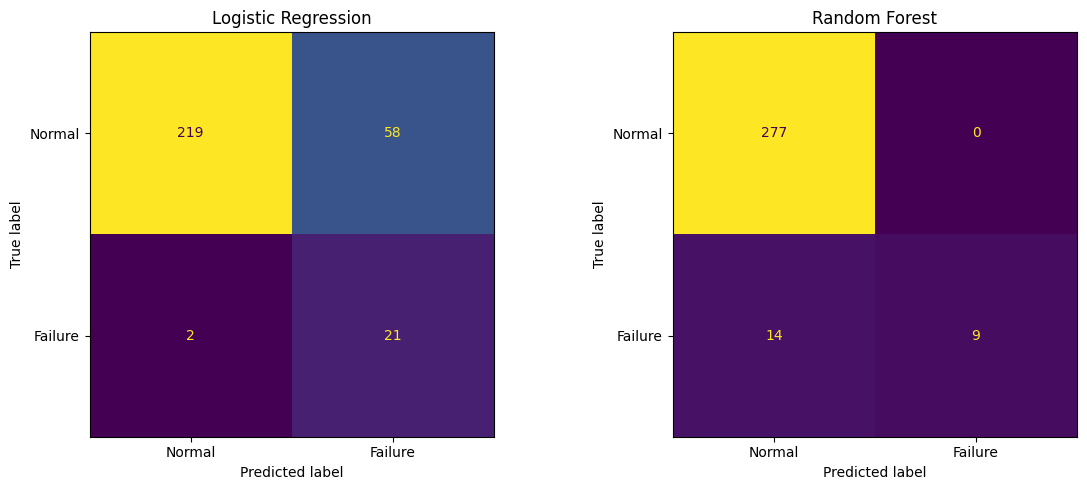

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=["Normal", "Failure"]
).plot(ax=axes[0], colorbar=False)

axes[0].set_title("Logistic Regression")

cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Normal", "Failure"]
).plot(ax=axes[1], colorbar=False)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

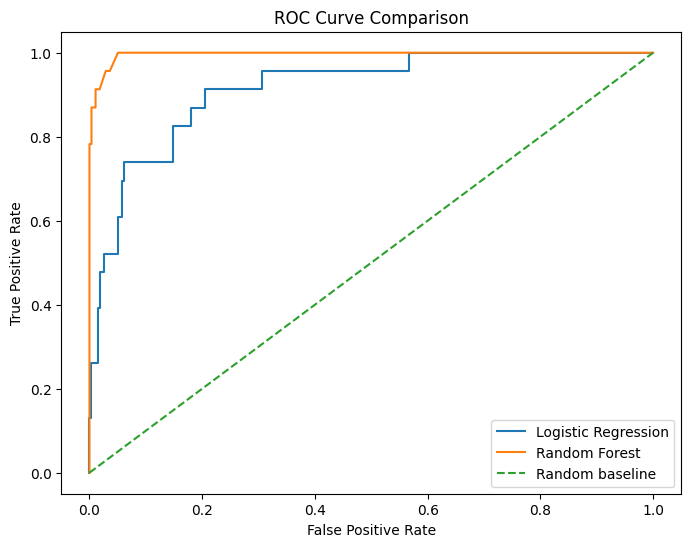

In [30]:
from sklearn.metrics import roc_curve

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr, tpr_lr,
    label="Logistic Regression"
)

plt.plot(
    fpr_rf, tpr_rf,
    label="Random Forest"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

,Feature,Importance
5,Runtime_Hours,0.242918
4,Energy_Consumption,0.164608
3,Pressure,0.126530
2,Vibration,0.123598
1,Humidity,0.108664
0,Temperature,0.089803
7,Energy_Per_Runtime,0.079454
6,Temperature_Deviation,0.064424


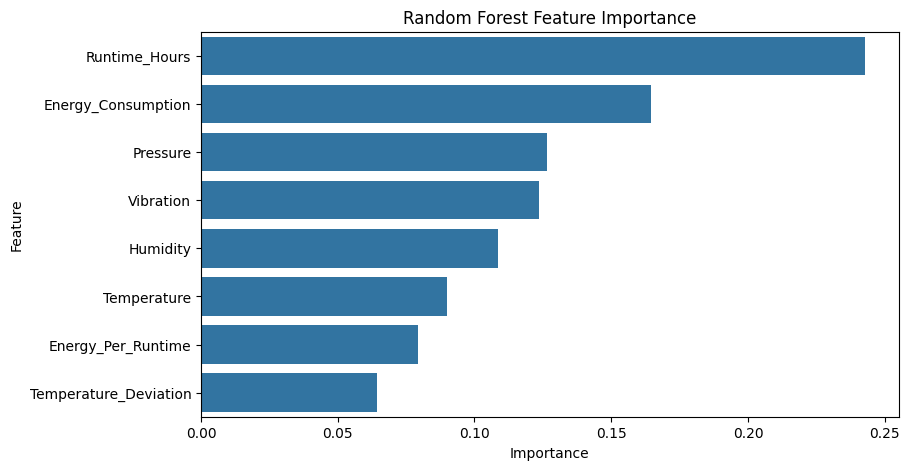

In [31]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.show()

Interpretation: Runtime hours is the most important feature, followed by energy consumption, pressure and vibration. Temperature deviation has the lowest importance among the eight features in this model.

### Feature Importance and Early Failure Indicators

The Random Forest feature-importance analysis identified **Runtime_Hours** as the most influential feature, followed by **Energy_Consumption, Pressure, and Vibration**. Humidity and Temperature had moderate importance, while Temperature_Deviation had the lowest importance among the eight input features.

In the synthetic dataset, potential failure indicators include high temperature, high humidity, increased vibration, low pressure, high energy consumption, and extended runtime. The failure label is assigned when at least two predefined sensor thresholds are exceeded or crossed.

These findings describe patterns learned from the simulated dataset. The thresholds and feature rankings are not validated indicators of real HVAC failures. Real-world sensor data and failure records would be required to establish reliable early-warning conditions.

In [32]:
import joblib

# Calculate the same IQR capping limits used during preprocessing
capping_limits = {}

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    capping_limits[col] = (lower, upper)

# Save model and preprocessing information together
artifact = {
    "model": rf_model,
    "features": list(X_train.columns),
    "capping_limits": capping_limits
}

joblib.dump(artifact, "hvac_model.pkl")

print("Model saved successfully!")

Model saved successfully!


### By Ashera Sage ###